# Volatility Surface: Heston Model, SVI Smiles and Calibration

**Goal.** Black-Scholes assumes one constant volatility, yet the market quotes a different
implied volatility for every strike and maturity: the **volatility surface**. This project
builds the two standard tools desks use to model it:

1. **Heston**, a stochastic-volatility model whose parameters have a financial meaning
   (mean reversion, vol of vol, spot-vol correlation), priced by Fourier inversion.
2. **SVI**, a five-parameter formula fitted smile by smile, with an arbitrage check.

**Data.** Option quotes are generated from a "true" Heston model plus bid-ask noise. This
lets us check that the calibration recovers parameters we know.

**Plan.** 1. Validate the Heston pricer · 2. Build a market surface · 3. Fit SVI smiles and
check for arbitrage · 4. Calibrate Heston back to the surface.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("volsurface.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/03-volatility-surface")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from volsurface import (HestonParams, heston_call, heston_monte_carlo, implied_vol_call, bs_call,
                        fit_svi, svi_total_variance, durrleman_g, calibrate_heston)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"
S0, r, q = 100.0, 0.03, 0.01

## 1. The Heston model and its Fourier pricer

$$dS_t = (r-q)S_t\,dt + \sqrt{v_t}\,S_t\,dW^S_t, \qquad
dv_t = \kappa(\theta - v_t)\,dt + \sigma\sqrt{v_t}\,dW^v_t, \qquad d\langle W^S, W^v\rangle_t = \rho\,dt$$

- $\kappa$: speed at which variance returns to its long-run level $\theta$
- $\sigma$: volatility of variance, which creates the **smile** (fat tails)
- $\rho < 0$: volatility rises when the stock falls, which creates the **skew**

The characteristic function of $\ln S_T$ is known in closed form, so a call price is a
one-dimensional integral (Gil-Pelaez): $C = S_0e^{-qT}P_1 - Ke^{-rT}P_2$. We validate it
against a brute-force Monte Carlo simulation of the two SDEs.

In [2]:
true = HestonParams(v0=0.04, kappa=1.5, theta=0.05, sigma=0.6, rho=-0.7)
print(true, f"\nFeller condition 2*kappa*theta - sigma^2 = {true.feller:.3f}")

strikes = np.array([80., 90., 100., 110., 120.])
fourier = heston_call(S0, strikes, 1.0, r, q, true)
mc, se = heston_monte_carlo(S0, strikes, 1.0, r, q, true, n_paths=300_000, n_steps=250)
pd.DataFrame({"Strike": strikes, "Fourier": fourier, "Monte Carlo": mc, "MC std error": se,
              "Difference": fourier - mc}).round(4)

HestonParams(v0=0.04, kappa=1.5, theta=0.05, sigma=0.6, rho=-0.7) 
Feller condition 2*kappa*theta - sigma^2 = -0.210


,Strike,Fourier,Monte Carlo,MC std error,Difference
0,80.0,23.2404,23.2302,0.0275,0.0102
1,90.0,15.1978,15.1919,0.0234,0.0059
2,100.0,8.3629,8.3654,0.0181,-0.0024
3,110.0,3.4829,3.4938,0.0123,-0.0109
4,120.0,1.0613,1.0745,0.0072,-0.0132


The Fourier prices agree with Monte Carlo within its error bars, and the Fourier pricer
is thousands of times faster: that speed is what makes calibration possible.

## 2. The market volatility surface

Quotes for 5 maturities and 15 strikes, converted to implied volatilities, plus random
noise of ±0.15 vol points to mimic bid-ask spreads.

In [3]:
maturities = np.array([0.25, 0.5, 1.0, 2.0, 3.0])
K_grid = np.linspace(70, 130, 15)
rng = np.random.default_rng(3)
market_vols = []
for T in maturities:
    prices = heston_call(S0, K_grid, T, r, q, true)
    iv = np.array([implied_vol_call(p, S0, k, T, r, q) for p, k in zip(prices, K_grid)])
    market_vols.append(iv + rng.normal(0, 0.0015, iv.size))
market_vols = np.array(market_vols)

surface = pd.DataFrame(market_vols * 100, index=[f"{T}y" for T in maturities], columns=K_grid.round(0).astype(int))
surface.iloc[:, ::2].round(2)

,70,79,87,96,104,113,121,130
0.25y,31.86,28.36,24.80,20.81,16.97,14.95,14.98,15.53
0.5y,30.05,26.97,23.78,20.69,17.05,14.96,14.44,15.05
1.0y,27.78,25.37,22.63,19.62,17.48,15.69,14.47,14.26
2.0y,25.63,23.80,22.03,20.01,18.65,17.04,15.62,15.21
3.0y,24.34,22.94,21.38,20.50,18.88,18.18,17.41,16.41


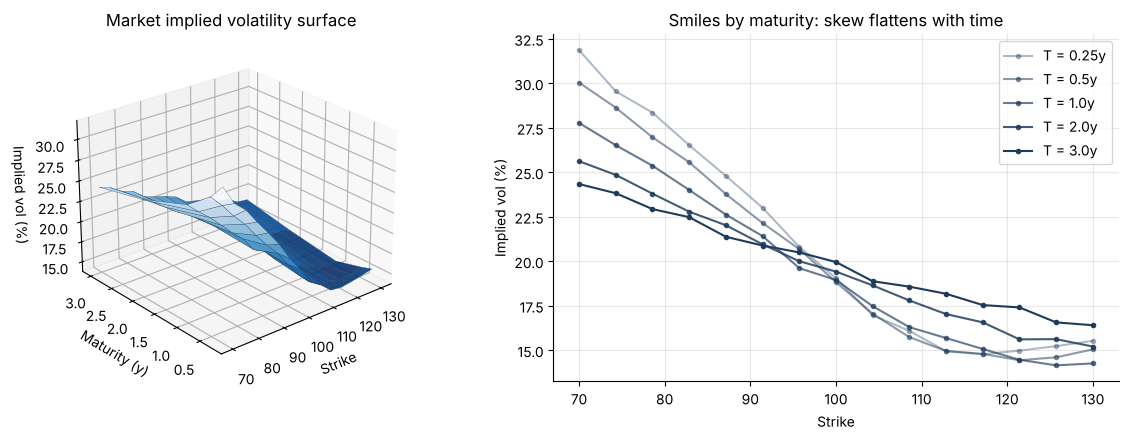

In [4]:
fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
KK, TT = np.meshgrid(K_grid, maturities)
ax.plot_surface(KK, TT, market_vols * 100, cmap="Blues_r", edgecolor=NAVY, linewidth=0.2, alpha=0.9)
ax.set(xlabel="Strike", ylabel="Maturity (y)", zlabel="Implied vol (%)", title="Market implied volatility surface")
ax.view_init(25, -130)
ax2 = fig.add_subplot(1, 2, 2)
for T, vols, a in zip(maturities, market_vols, np.linspace(0.35, 1, len(maturities))):
    ax2.plot(K_grid, vols * 100, marker="o", ms=3, color=NAVY, alpha=a, label=f"T = {T}y")
ax2.set(xlabel="Strike", ylabel="Implied vol (%)", title="Smiles by maturity: skew flattens with time")
ax2.legend()
plt.tight_layout(); plt.savefig("images/surface.png", dpi=150); plt.show()

**Reading the surface.** Low strikes trade at higher volatility (crash protection is
expensive), and the skew is steepest for short maturities, the typical shape of equity
index options.

## 3. SVI smiles and the arbitrage check

For each maturity, fit the raw SVI formula to total implied variance $w(k) = \sigma^2_{imp}(k)\,T$
as a function of log-moneyness $k = \ln(K/F)$:

$$w(k) = a + b\left(\rho(k-m) + \sqrt{(k-m)^2 + s^2}\right)$$

A fitted smile can still imply negative probabilities (butterfly arbitrage). Durrleman's
function $g(k)$, built from $w$ and its two derivatives, must stay positive: it is
proportional to the implied risk-neutral density.

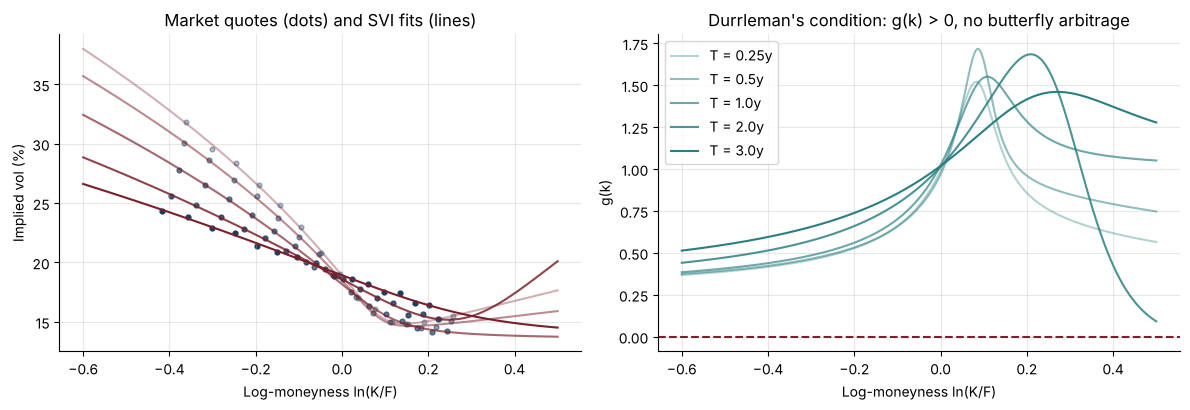

,Maturity,a,b,rho,m,s,RMSE (vol pts),min g(k)
0,0.25,0.0044,0.0270,-0.7041,0.0881,0.0589,0.1862,0.3682
1,0.50,0.0096,0.0428,-0.8330,0.0891,0.0475,0.1226,0.3741
2,1.00,0.0181,0.0619,-0.9990,0.0997,0.0988,0.1550,0.3846
3,2.00,0.0090,0.2232,0.2209,0.2849,0.1702,0.1184,0.0918
4,3.00,0.0532,0.0937,-0.9990,0.2298,0.2627,0.1615,0.5134


In [5]:
svi_rows, fig, axes = [], *plt.subplots(1, 2, figsize=(12, 4.2))
k_fine = np.linspace(-0.6, 0.5, 300)
for T, vols, a in zip(maturities, market_vols, np.linspace(0.35, 1, len(maturities))):
    F = S0 * np.exp((r - q) * T)
    k = np.log(K_grid / F)
    params = fit_svi(k, vols**2 * T)
    fit_vols = np.sqrt(svi_total_variance(k, *params) / T)
    svi_rows.append({"Maturity": T, **dict(zip(["a", "b", "rho", "m", "s"], params)),
                     "RMSE (vol pts)": np.sqrt(np.mean((fit_vols - vols) ** 2)) * 100,
                     "min g(k)": durrleman_g(k_fine, params).min()})
    axes[0].scatter(k, vols * 100, color=NAVY, alpha=a, s=12)
    axes[0].plot(k_fine, np.sqrt(svi_total_variance(k_fine, *params) / T) * 100, color=BORDEAUX, alpha=a)
    axes[1].plot(k_fine, durrleman_g(k_fine, params), color=TEAL, alpha=a, label=f"T = {T}y")
axes[0].set(xlabel="Log-moneyness ln(K/F)", ylabel="Implied vol (%)", title="Market quotes (dots) and SVI fits (lines)")
axes[1].axhline(0, color=BORDEAUX, ls="--"); axes[1].legend()
axes[1].set(xlabel="Log-moneyness ln(K/F)", ylabel="g(k)", title="Durrleman's condition: g(k) > 0, no butterfly arbitrage")
plt.tight_layout(); plt.savefig("images/svi.png", dpi=150); plt.show()
pd.DataFrame(svi_rows).round(4)

Every smile is fitted to within the bid-ask noise (RMSE about 0.1 vol point) and $g(k)$
stays positive everywhere: the surface can be used to price without creating arbitrage.

**A practical caveat.** SVI parameters are not unique when quotes cover a narrow strike
range: the 2y smile is reproduced with a different $(\rho, m)$ pair than its neighbours.
This instability across maturities is why desks often move to constrained versions such
as SSVI, which tie the smiles together.

## 4. Calibrating Heston to the whole surface

SVI fits each maturity separately. Heston must explain the **whole surface with five
parameters**, which makes it consistent across maturities and usable for exotic products.
We minimise the vega-weighted pricing errors (approximately the implied-vol errors),
starting from a deliberately wrong initial guess.

In [6]:
import time
t0 = time.time()
fitted, rmse = calibrate_heston(S0, r, q, maturities, K_grid, market_vols)
print(f"Calibration time: {time.time() - t0:.1f} s   RMSE: {rmse * 100:.3f} vol points")
pd.DataFrame({"True": vars(true), "Calibrated": vars(fitted)}).round(4)

Calibration time: 3.7 s   RMSE: 0.162 vol points


,True,Calibrated
v0,0.04,0.0401
kappa,1.50,1.4635
theta,0.05,0.0500
sigma,0.60,0.5924
rho,-0.70,-0.7006


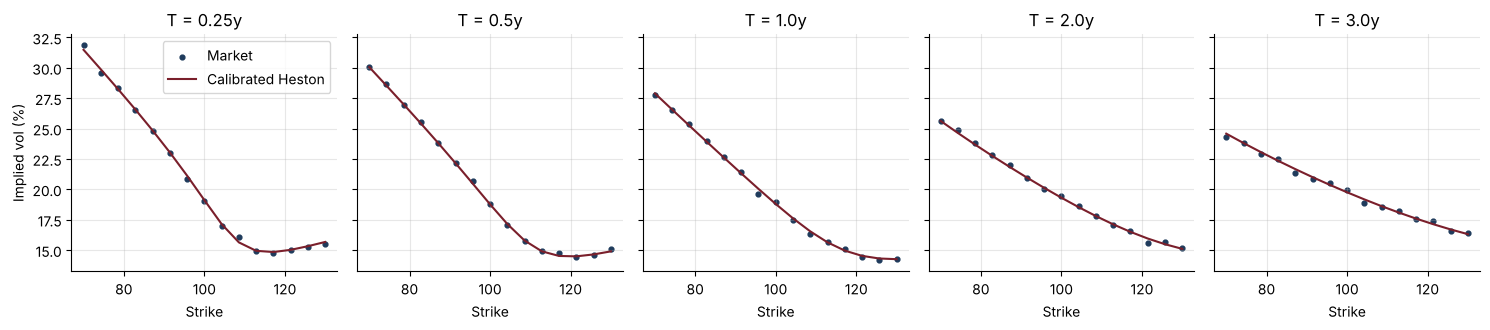

In [7]:
fig, axes = plt.subplots(1, len(maturities), figsize=(15, 3.4), sharey=True)
for ax, T, vols in zip(axes, maturities, market_vols):
    model = [implied_vol_call(p, S0, k, T, r, q) for p, k in zip(heston_call(S0, K_grid, T, r, q, fitted), K_grid)]
    ax.scatter(K_grid, vols * 100, color=NAVY, s=12, label="Market")
    ax.plot(K_grid, np.array(model) * 100, color=BORDEAUX, label="Calibrated Heston")
    ax.set(title=f"T = {T}y", xlabel="Strike")
axes[0].set_ylabel("Implied vol (%)"); axes[0].legend()
plt.tight_layout(); plt.savefig("images/heston_fit.png", dpi=150); plt.show()

## Conclusions
- The Heston Fourier pricer matches Monte Carlo and prices a full surface in milliseconds.
- SVI reproduces each smile within the bid-ask noise and passes the butterfly-arbitrage check.
- The calibration recovers the true parameters from noisy quotes, which validates the whole
  chain: pricer, implied-vol inversion and optimiser.
- **Next steps:** calendar-arbitrage checks across maturities (SSVI), the Dupire local
  volatility surface, and pricing the autocall of project 02 under Heston.